# 02 · Clustering — K-Means on Dark Stores
**Component 2: implementation of a clustering algorithm.** Run `01_Create_Dataset` first.

Reads `dataset/store_features.csv` and `dataset/clean_food_orders.csv` · creates `results/02_clustering/`.

In [1]:
# ---- Only on Google Colab (skip on your own computer) ----
# !pip install -q hmmlearn
# from google.colab import drive; drive.mount("/content/drive")
# %cd /content/drive/MyDrive/QuickCommerce_ML_Project_Final

import os, json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
import joblib
warnings.filterwarnings("ignore")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
DATE = "%d-%m-%Y"

def inr(x):
    # Indian digit grouping: 113390 -> 1,13,390
    s = f"{abs(x):.0f}"; head, tail = s[:-3], s[-3:]; parts = []
    while len(head) > 2:
        parts.insert(0, head[-2:]); head = head[:-2]
    if head: parts.insert(0, head)
    return ("-" if x < 0 else "") + ",".join(parts + [tail])

# chart style — colour-blind-safe palette in fixed order
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 9.5, "font.size": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 1.5, "figure.dpi": 110, "legend.frameon": False,
})

OUT = "results/02_clustering"                      # every file this notebook creates goes here
os.makedirs(OUT, exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=240, bbox_inches="tight")
    plt.show()

In [2]:
stores = pd.read_csv("dataset/store_features.csv", index_col="store_id", parse_dates=["first_order"])
clean = pd.read_csv("dataset/clean_food_orders.csv", parse_dates=["order_datetime", "order_date"])
clean["night"] = clean.order_hour.isin([22, 23, 0, 1, 2, 3, 4, 5])
print(f"Store table: {stores.shape[0]} stores × {stores.shape[1]} columns  |  clean orders: {inr(len(clean))}")
stores.head()

Store table: 58 stores × 24 columns  |  clean orders: 1,13,390


,city,area_type,first_order,days_open,orders_per_day,avg_basket_value,avg_items,discount_pct,night_share,morning_share,late_rate,avg_delivery_min,avg_distance_km,stockout_rate,cancel_rate,complaint_rate,member_share,share_fruit_veg,share_snacks_bev,share_instant_frozen,share_dairy_bread_eggs,share_atta_rice_dal,share_icecream_desserts,share_sweets
store_id,,,,,,,,,,,,,,,,,,,,,,,,
DS001,Bengaluru,Student / PG Hub,2025-01-01,638,5.122,449.922,4.491,7.782,37.362,9.608,27.767,11.302,1.749,13.494,1.591,5.171,18.727,40.606,69.400,47.368,49.969,27.020,28.550,5.630
DS002,Bengaluru,Residential,2025-01-01,638,3.397,446.142,4.461,7.772,23.950,18.182,28.898,11.285,1.730,12.137,1.154,5.122,17.120,48.408,61.375,43.609,57.176,29.303,21.735,5.630
DS003,Bengaluru,Premium Residential,2025-01-01,638,3.150,452.856,4.489,7.726,25.224,17.413,29.838,11.353,1.741,11.592,1.791,5.970,16.766,47.363,62.289,43.234,56.219,30.000,22.090,6.020
DS004,Bengaluru,Premium Residential,2025-01-01,638,6.282,441.708,4.465,7.743,23.328,18.089,28.593,11.262,1.706,12.799,1.572,5.289,17.839,47.779,61.053,41.866,58.757,29.466,22.954,5.639
DS005,Bengaluru,Residential,2025-09-08,388,4.575,451.546,4.496,7.033,23.887,17.239,28.982,11.165,1.741,13.296,2.028,4.958,18.592,46.873,63.549,42.761,57.014,30.028,20.958,5.634


## 2.1 Algorithm and justification
**K-Means** splits *n* points into *k* groups by minimising the within-cluster sum of squared distances to the
cluster centres:
$$J=\sum_{j=1}^{k}\sum_{x\in C_j}\lVert x-\mu_j\rVert^2$$
It alternates (1) assigning each store to the nearest centre and (2) moving each centre to the mean of its stores,
until nothing changes.

**Why K-Means here:** all store features are numeric and comparable after standardisation; the expected groups are
compact "types of store"; every centre is an *average store profile*, which is easy to explain as a stocking plan;
it is fast and repeatable with many random starts. Agglomerative (Ward) clustering and a Gaussian Mixture Model are
also run in 2.6 as a check.

## 2.2 Feature selection
Two questions decide whether a store feature is used for grouping:
1. **Is it a demand feature?** Clusters should become stocking and staffing plans, so they are built from *what* is
   ordered, *when* and *how much*. Service outcomes (late deliveries, delivery time, stock-outs, cancellations,
   complaints) are results of daily conditions; they are used later to *describe* the clusters.
2. **Does it really differ between stores?** Each store rate is estimated from about 2,000 orders, so it varies a little
   by chance alone. The **signal-to-noise ratio** compares the observed between-store variance with the variance that
   sampling noise alone would produce: **≈ 1 means the differences are pure chance**.

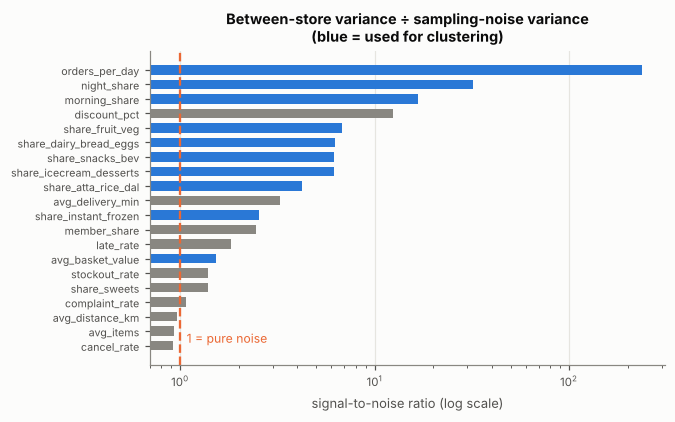

,cancel_rate,avg_items,avg_distance_km,complaint_rate,share_sweets,stockout_rate,avg_basket_value,late_rate,member_share,share_instant_frozen,avg_delivery_min,share_atta_rice_dal,share_icecream_desserts,share_snacks_bev,share_dairy_bread_eggs,share_fruit_veg,discount_pct,morning_share,night_share,orders_per_day
signal / noise,0.920,0.930,0.970,1.070,1.390,1.400,1.530,1.830,2.450,2.550,3.270,4.250,6.160,6.180,6.240,6.780,12.430,16.780,31.940,235.900


Correlation of discount share with store opening date: -0.92


In [3]:
CANDIDATES = [c for c in stores.columns if c not in ("city", "area_type", "first_order", "days_open")]
CLUSTER_FEATURES = ["orders_per_day", "night_share", "morning_share", "share_fruit_veg", "share_snacks_bev",
                    "share_dairy_bread_eggs", "share_atta_rice_dal", "share_icecream_desserts", "share_instant_frozen",
                    "avg_basket_value"]
n_orders = clean.groupby("store_id").size()
deliv = clean[clean.order_status.ne("Cancelled")]
n_deliv = deliv.groupby("store_id").size()
by_store = clean.groupby("store_id")
def noise_var(f):
    # variance of a store-level feature expected from sampling noise alone
    if f == "orders_per_day":   return (clean.groupby(["store_id", "order_date"]).size().groupby("store_id").var() / stores.days_open).mean()
    if f == "avg_basket_value": return (by_store.item_total.var() / n_orders).mean()
    if f == "avg_items":        return (by_store.items_count.var() / n_orders).mean()
    if f == "avg_distance_km":  return (by_store.distance_km.var() / n_orders).mean()
    if f == "avg_delivery_min": return (deliv.groupby("store_id").actual_delivery_minutes.var() / n_deliv).mean()
    if f == "discount_pct":     return ((clean.discount / clean.item_total * 100).groupby(clean.store_id).var() / n_orders).mean()
    n = n_deliv if f == "late_rate" else n_orders                     # rates in %: binomial variance
    p = stores[f] / 100
    return (p * (1 - p) / n * 1e4).mean()
snr = pd.Series({f: stores[f].var() / noise_var(f) for f in CANDIDATES}).sort_values()
snr.to_frame("signal_to_noise").assign(used=lambda t: t.index.isin(CLUSTER_FEATURES)).to_csv(f"{OUT}/feature_signal_to_noise.csv")
fig, ax = plt.subplots(figsize=(6.2, 3.9))
ax.barh(snr.index, snr.values, color=[BLUE if c in CLUSTER_FEATURES else MUTED for c in snr.index], height=0.65)
ax.axvline(1, color=ORANGE, lw=1.5, ls="--"); ax.text(1.08, 0.2, "1 = pure noise", color=ORANGE, fontsize=8)
ax.set_xscale("log")
ax.set(title="Between-store variance ÷ sampling-noise variance\n(blue = used for clustering)", xlabel="signal-to-noise ratio (log scale)")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); save_fig(fig, "feature_selection")
display(snr.round(2).to_frame("signal / noise").T)
print(f"Correlation of discount share with store opening date: {np.corrcoef(stores.first_order.astype('int64'), stores.discount_pct)[0, 1]:.2f}")

**Selected features (demand profile):** orders per day, night share, morning share, the share of baskets containing
each of the six main food categories, and average basket value.
- **Pure noise (ratio ≈ 1), not used:** cancellation rate, complaint rate, items per order, delivery distance; sweets
  share (1.4) is also close to noise.
- **Service outcomes, not used for grouping:** late rate, delivery time, stock-out rate.
- **Customer attribute, not used:** member share.
- **Discount share** differs strongly (12.4) but follows *store age* (correlation −0.92 with opening date) — not demand.
- **Average basket value** is weak overall (1.5) but carries the office stores' real difference; the check in 2.6 shows
  it is needed.

All features are standardised: $z = (x-\mu)/\sigma$.

In [4]:
scaler = StandardScaler().fit(stores[CLUSTER_FEATURES])
X = scaler.transform(stores[CLUSTER_FEATURES])
print("Clustering matrix:", X.shape, "| mean ≈", X.mean().round(3), "| std ≈", X.std().round(3))

Clustering matrix: (58, 10) | mean ≈ -0.0 | std ≈ 1.0


## 2.3 Choosing the number of clusters k (elbow, silhouette, Davies–Bouldin, Calinski–Harabasz)

,inertia (WCSS),silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,cluster sizes
k,,,,,
2,231.237,0.606,0.584,84.462,"[47, 11]"
3,188.374,0.419,0.896,57.172,"[42, 11, 5]"
4,159.668,0.285,1.157,47.386,"[29, 14, 11, 4]"
5,136.993,0.296,1.117,42.848,"[19, 15, 11, 9, 4]"
6,120.526,0.252,1.235,39.647,"[19, 15, 9, 8, 4, 3]"
7,108.912,0.253,0.979,36.766,"[19, 15, 9, 8, 4, 2, 1]"
8,100.322,0.209,1.146,34.153,"[18, 13, 9, 5, 5, 4, 3, 1]"


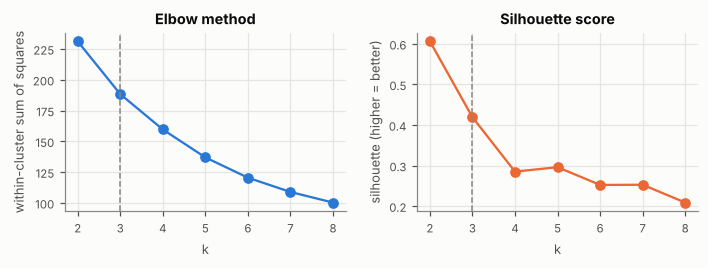

In [5]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    rows.append({"k": k, "inertia (WCSS)": km.inertia_, "silhouette ↑": silhouette_score(X, km.labels_),
                 "Davies–Bouldin ↓": davies_bouldin_score(X, km.labels_),
                 "Calinski–Harabasz ↑": calinski_harabasz_score(X, km.labels_),
                 "cluster sizes": sorted(np.bincount(km.labels_).tolist(), reverse=True)})
ksel = pd.DataFrame(rows).set_index("k")
ksel.to_csv(f"{OUT}/k_selection.csv")
display(ksel)
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.5))
axes[0].plot(ksel.index, ksel["inertia (WCSS)"], color=BLUE, marker="o")
axes[0].set(title="Elbow method", xlabel="k", ylabel="within-cluster sum of squares")
axes[1].plot(ksel.index, ksel["silhouette ↑"], color=ORANGE, marker="o")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="silhouette (higher = better)")
for ax in axes: ax.axvline(3, color=MUTED, ls="--", lw=1)
plt.tight_layout(); save_fig(fig, "k_selection")

**Choice: k = 3.** k = 2 has the highest silhouette, but it only separates the student/PG-hub stores from all others.
k = 3 is the next best on every metric, the elbow bends there, and it separates a third, business-relevant group
(office / tech-park stores). Beyond k = 3 all metrics get clearly worse.

## 2.4 Final model and output

In [6]:
K = 3
t0 = time.perf_counter()
kmeans = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
KMEANS_TIME = time.perf_counter() - t0
# name clusters from their centres (names stay correct whatever label numbers K-Means gives)
prof = stores[CLUSTER_FEATURES].groupby(kmeans.labels_).mean()
night_c, office_c = prof.night_share.idxmax(), prof.night_share.idxmin()
NAMES = {night_c: "Late-night snack hubs", office_c: "Daytime office stores"}
NAMES.update({c: "Family residential stores" for c in range(K) if c not in NAMES})
stores["cluster_id"] = kmeans.labels_
stores["cluster"] = pd.Series(kmeans.labels_, index=stores.index).map(NAMES)
ORDER = ["Family residential stores", "Late-night snack hubs", "Daytime office stores"]
CCOL = dict(zip(ORDER, [BLUE, ORANGE, AQUA]))
print(f"K-Means fitted in {KMEANS_TIME*1000:.0f} ms (50 random starts)")
display(stores.cluster.value_counts().reindex(ORDER).to_frame("stores"))
centres = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=CLUSTER_FEATURES).rename(index=NAMES).reindex(ORDER)
print("Cluster centres (original units):")
centres.round(1)

K-Means fitted in 20 ms (50 random starts)


,stores
cluster,
Family residential stores,42
Late-night snack hubs,11
Daytime office stores,5


Cluster centres (original units):


,orders_per_day,night_share,morning_share,share_fruit_veg,share_snacks_bev,share_dairy_bread_eggs,share_atta_rice_dal,share_icecream_desserts,share_instant_frozen,avg_basket_value
Family residential stores,3.600,24.000,18.400,47.100,61.600,58.200,30.100,23.600,41.800,445.000
Late-night snack hubs,4.400,37.700,9.000,40.000,68.700,51.000,25.600,29.000,45.700,440.300
Daytime office stores,3.900,15.200,14.600,51.100,60.200,60.300,33.300,23.200,41.700,459.200


## 2.5 Visualising the clusters

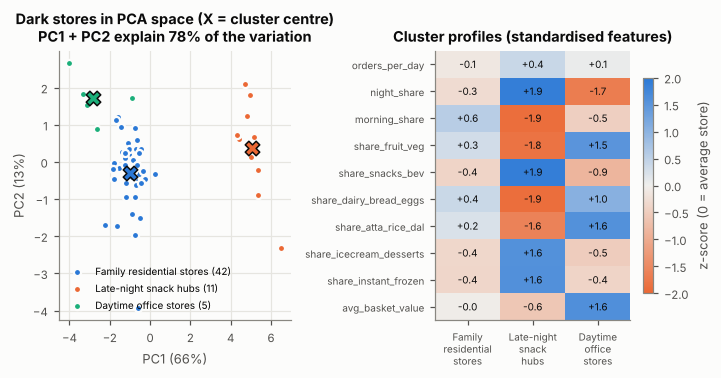

In [7]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X); C = pca.transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.5), gridspec_kw={"width_ratios": [1, 1.05]})
for name in ORDER:
    m = stores.cluster.eq(name).values
    axes[0].scatter(P[m, 0], P[m, 1], s=22, color=CCOL[name], edgecolor="#fcfcfb", lw=1.5, label=f"{name} ({m.sum()})")
for i, name in NAMES.items():
    axes[0].scatter(C[i, 0], C[i, 1], s=90, marker="X", color=CCOL[name], edgecolor=INK, lw=1)
axes[0].set(title=f"Dark stores in PCA space (X = cluster centre)\nPC1 + PC2 explain {pca.explained_variance_ratio_.sum():.0%} of the variation",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[0].legend(fontsize=6.5, loc="lower left")
z = pd.DataFrame(X, columns=CLUSTER_FEATURES, index=stores.index).groupby(stores.cluster).mean().reindex(ORDER)
div = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])
im = axes[1].imshow(z.T.values, cmap=div, vmin=-2, vmax=2, aspect="auto")
axes[1].set_xticks(range(K)); axes[1].set_xticklabels([n.replace(" ", "\n") for n in ORDER], fontsize=6.5)
axes[1].set_yticks(range(len(CLUSTER_FEATURES))); axes[1].set_yticklabels(CLUSTER_FEATURES, fontsize=6.5)
axes[1].grid(False)
for i in range(z.shape[1]):
    for j in range(K):
        axes[1].text(j, i, f"{z.T.values[i, j]:+.1f}", ha="center", va="center", fontsize=6.5, color=INK)
fig.colorbar(im, ax=axes[1], shrink=0.8, label="z-score (0 = average store)")
axes[1].set_title("Cluster profiles (standardised features)")
plt.tight_layout(); save_fig(fig, "clusters_pca_and_profiles")

In [8]:
profile = stores.groupby("cluster")[CLUSTER_FEATURES + ["late_rate", "complaint_rate", "stockout_rate"]].mean().reindex(ORDER).T
profile.columns.name = None
profile.round(2).to_csv(f"{OUT}/cluster_profiles.csv")
display(profile.round(1))
print("Location type of the stores in each cluster:")
loc = pd.crosstab(stores.cluster, stores.area_type).reindex(ORDER)
loc.to_csv(f"{OUT}/cluster_vs_location.csv")
loc

,Family residential stores,Late-night snack hubs,Daytime office stores
orders_per_day,3.600,4.400,3.900
night_share,24.000,37.700,15.200
morning_share,18.400,9.000,14.600
share_fruit_veg,47.100,40.000,51.100
share_snacks_bev,61.600,68.700,60.200
share_dairy_bread_eggs,58.200,51.000,60.300
share_atta_rice_dal,30.100,25.600,33.300
share_icecream_desserts,23.600,29.000,23.200
share_instant_frozen,41.800,45.700,41.700
avg_basket_value,445.000,440.300,459.200


Location type of the stores in each cluster:


area_type,Office / Tech Park,Premium Residential,Residential,Student / PG Hub
cluster,,,,
Family residential stores,0,11,31,0
Late-night snack hubs,0,0,0,11
Daytime office stores,5,0,0,0


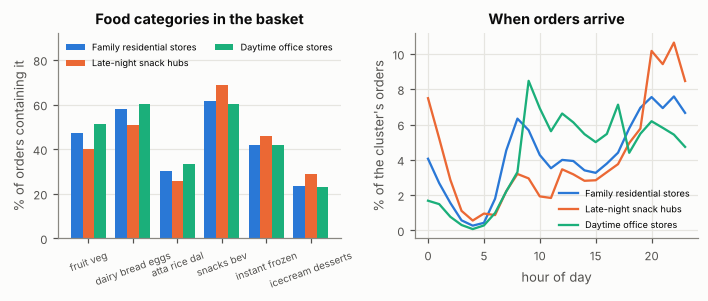

In [9]:
cats = ["share_fruit_veg", "share_dairy_bread_eggs", "share_atta_rice_dal", "share_snacks_bev", "share_instant_frozen", "share_icecream_desserts"]
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.8))
xpos = np.arange(len(cats)); w = 0.26
for i, name in enumerate(ORDER):
    axes[0].bar(xpos + (i - 1) * w, profile.loc[cats, name], w, color=CCOL[name], label=name)
axes[0].set_xticks(xpos); axes[0].set_xticklabels([c.replace("share_", "").replace("_", " ") for c in cats], fontsize=6.5, rotation=20)
axes[0].set(title="Food categories in the basket", ylabel="% of orders containing it"); axes[0].legend(fontsize=6, ncol=2); axes[0].set_ylim(0, 92)
axes[0].grid(axis="x", visible=False)
hours = clean.assign(cluster=clean.store_id.map(stores.cluster)).groupby(["cluster", "order_hour"]).size()
hours = hours / hours.groupby(level=0).transform("sum") * 100
for name in ORDER:
    axes[1].plot(hours.loc[name].index, hours.loc[name].values, color=CCOL[name], label=name)
axes[1].set(title="When orders arrive", xlabel="hour of day", ylabel="% of the cluster's orders"); axes[1].legend(fontsize=6)
plt.tight_layout(); save_fig(fig, "cluster_baskets_and_hours")

## 2.6 Evaluation of the clustering
| Metric | Meaning | Good value |
|---|---|---|
| **Silhouette** | how much closer a store is to its own cluster than to the next one (−1 … 1) | > 0.25 reasonable, > 0.5 strong |
| **Davies–Bouldin** | average similarity between each cluster and its most similar one | lower is better |
| **Calinski–Harabasz** | between-cluster spread ÷ within-cluster spread | higher is better |
| **Stability (ARI)** | agreement of the result when K-Means is restarted with other seeds (1 = identical) | close to 1 |

In [10]:
labels = kmeans.labels_
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
gmm_store = GaussianMixture(n_components=K, n_init=10, random_state=SEED).fit(X).predict(X)
stab = [adjusted_rand_score(labels, KMeans(K, n_init=10, random_state=s).fit_predict(X)) for s in range(20)]
CLUSTER_METRICS = {"silhouette": silhouette_score(X, labels), "davies_bouldin": davies_bouldin_score(X, labels),
                   "calinski_harabasz": calinski_harabasz_score(X, labels), "stability_ari": float(np.mean(stab))}
comp = pd.DataFrame({
    "K-Means": [silhouette_score(X, labels), davies_bouldin_score(X, labels), calinski_harabasz_score(X, labels), 1.0],
    "Agglomerative (Ward)": [silhouette_score(X, agg), davies_bouldin_score(X, agg), calinski_harabasz_score(X, agg), adjusted_rand_score(labels, agg)],
    "Gaussian Mixture": [silhouette_score(X, gmm_store), davies_bouldin_score(X, gmm_store), calinski_harabasz_score(X, gmm_store), adjusted_rand_score(labels, gmm_store)],
}, index=["silhouette ↑", "Davies–Bouldin ↓", "Calinski–Harabasz ↑", "agreement with K-Means (ARI)"])
comp.to_csv(f"{OUT}/cluster_metrics.csv")
print(f"Stability of K-Means over 20 restarts: mean ARI = {np.mean(stab):.2f} (min {np.min(stab):.2f})")
comp

Stability of K-Means over 20 restarts: mean ARI = 0.85 (min 0.56)


,K-Means,Agglomerative (Ward),Gaussian Mixture
silhouette ↑,0.419,0.414,0.419
Davies–Bouldin ↓,0.896,0.767,0.896
Calinski–Harabasz ↑,57.172,55.948,57.172
agreement with K-Means (ARI),1.000,0.943,1.000


**Check — is basket value needed?** K-Means is re-run with the same settings but without `avg_basket_value`.

In [11]:
X9 = StandardScaler().fit_transform(stores[[f for f in CLUSTER_FEATURES if f != "avg_basket_value"]])
l9 = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit_predict(X9)
print(f"Without basket value: silhouette {silhouette_score(X9, l9):.3f} (with it: {CLUSTER_METRICS['silhouette']:.3f}), "
      f"cluster sizes {sorted(np.bincount(l9).tolist(), reverse=True)}")
print("Where the stores go without basket value:")
pd.crosstab(stores.area_type, pd.Series(l9, index=stores.index).map(lambda c: f"cluster {c}"))

Without basket value: silhouette 0.268 (with it: 0.419), cluster sizes [25, 22, 11]
Where the stores go without basket value:


col_0,cluster 0,cluster 1,cluster 2
area_type,,,
Office / Tech Park,0,1,4
Premium Residential,0,6,5
Residential,0,18,13
Student / PG Hub,11,0,0


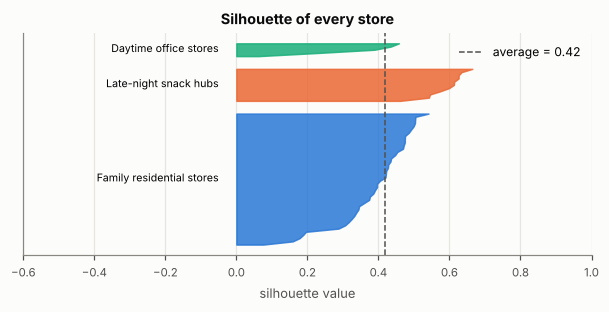

Stores with negative silhouette (possibly mis-assigned): 0 of 58


In [12]:
sil = silhouette_samples(X, labels)
stores["silhouette"] = sil
fig, ax = plt.subplots(figsize=(5.6, 2.9))
y0 = 0
for name in ORDER:
    v = np.sort(sil[stores.cluster.eq(name).values])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=CCOL[name], alpha=0.85)
    ax.text(-0.05, y0 + len(v) / 2, name, ha="right", va="center", fontsize=7)
    y0 += len(v) + 3
ax.axvline(CLUSTER_METRICS["silhouette"], color=INK2, ls="--", lw=1, label=f"average = {CLUSTER_METRICS['silhouette']:.2f}")
ax.set(title="Silhouette of every store", xlabel="silhouette value", yticks=[], xlim=(-0.6, 1)); ax.legend(fontsize=8)
plt.tight_layout(); save_fig(fig, "silhouette_per_store")
print(f"Stores with negative silhouette (possibly mis-assigned): {(sil < 0).sum()} of {len(sil)}")

## 2.7 Interpretation of the clusters
- **Family residential stores** (42 stores, residential and premium residential areas) — the strongest **morning peak**
  (18% of orders at 6–10 am) and a second peak in the evening; dairy, bread & eggs in 58% and fruits & vegetables in
  47% of baskets → stock milk, bread and fresh produce before 6 am; morning and evening rider shifts.
- **Late-night snack hubs** (11 stores, student / PG hubs) — 38% of orders at night (10 pm–6 am); the most snacks &
  beverages (69% of baskets), ice cream and instant / frozen food; the fewest staples, fresh produce and dairy → stock
  packaged snacks, cold drinks, frozen food and ice cream for the night; riders on late shifts.
- **Daytime office stores** (5 stores, office / tech parks) — the fewest night orders (15%), a sharp 9 am peak; the
  highest basket value (₹459) and the highest shares of fresh food, dairy and staples → weekday daytime stock; lighter
  night staffing.

The clusters were found **without** using the location type, yet they match it exactly. Late rate, complaints and
stock-outs hardly differ between clusters: they depend on daily conditions (weather, festivals) — the subject of
notebook 03.

## 2.8 Save the clustering files

In [13]:
stores.round(4).to_csv(f"{OUT}/store_clusters.csv")
joblib.dump({"scaler": scaler, "kmeans": kmeans, "features": CLUSTER_FEATURES, "names": NAMES}, f"{OUT}/kmeans_model.joblib")
json.dump({"k": K, **{k: round(v, 4) for k, v in CLUSTER_METRICS.items()}, "fit_time_ms": round(KMEANS_TIME * 1000, 1),
           "n_stores": len(stores), "cluster_sizes": stores.cluster.value_counts().reindex(ORDER).to_dict()},
          open(f"{OUT}/summary.json", "w"), indent=2)
for f in sorted(os.listdir(OUT)):
    print(f"{OUT}/{f}")

results/02_clustering/cluster_baskets_and_hours.png
results/02_clustering/cluster_metrics.csv
results/02_clustering/cluster_profiles.csv
results/02_clustering/cluster_vs_location.csv
results/02_clustering/clusters_pca_and_profiles.png
results/02_clustering/feature_selection.png
results/02_clustering/feature_signal_to_noise.csv
results/02_clustering/k_selection.csv
results/02_clustering/k_selection.png
results/02_clustering/kmeans_model.joblib
results/02_clustering/silhouette_per_store.png
results/02_clustering/store_clusters.csv
results/02_clustering/summary.json
